# Experiment 06 — Scalability Analysis

## E1. Data Scalability — Khả năng mở rộng theo lượng dữ liệu

### 1. Mục tiêu

Thí nghiệm đánh giá khả năng mở rộng của DeepKoopFormer khi quy mô dữ liệu huấn luyện tăng lên.

Cụ thể, chúng ta nghiên cứu:

- **Độ chính xác:** Lượng dữ liệu huấn luyện ảnh hưởng thế nào đến MSE và MAE?
- **Chi phí tính toán:** Thời gian huấn luyện và lượng bộ nhớ GPU tăng như thế nào?
- **Hiệu quả kiến trúc:** Koopman layer có mang lại lợi ích về độ chính xác đủ để bù đắp chi phí tính toán so với PatchTST thuần không?

### 2. Thiết kế thực nghiệm

Sử dụng hai mô hình từ Ablation Study:

- **PatchTST:** Mô hình cơ sở sử dụng Transformer.
- **KoopPatchTST_Full:** Mô hình tích hợp Koopman operator và chính quy hóa Lyapunov.

Thực nghiệm trên hai bộ dữ liệu:

- **Electricity:** Chuỗi thời gian gồm 6 biến.
- **CMIP6 Wind:** Chuỗi thời gian gồm 5 biến.

Các mức dữ liệu huấn luyện: **25%, 50%, 75% và 100%**.

Giữ cố định các siêu tham số:

| Tham số | Giá trị |
|---|---|
| Patch Length | 120 |
| Forecast Horizon | 8 |
| Epochs | 4000 |
| Learning Rate | 0.0003 |
| Random Seed | 7 |
| Optimizer | Adam |

**Tổng số cấu hình:**

2 datasets × 2 models × 4 training sizes = **16 lượt huấn luyện**.

### 3. Phương pháp thực hiện

1. Giữ nguyên tập kiểm tra (Test Set) để đảm bảo khả năng so sánh.
2. Lấy 25%, 50%, 75% và 100% phần dữ liệu Train, ưu tiên các đoạn gần ranh giới Test để giữ cùng thời điểm kết thúc huấn luyện.
3. Chuẩn hóa dữ liệu bằng Min-Max Scaling, fit riêng trên mỗi phần Train và áp dụng cùng scaler cho Test.
4. Huấn luyện các mô hình với cùng cấu hình và số epochs.
5. Đánh giá sai số trên thang đo gốc để tránh sai lệch do các scaler khác nhau.
6. Ghi nhận thời gian huấn luyện, thời gian trung bình mỗi epoch, số tham số và peak GPU memory.

### 4. Kết quả kỳ vọng

Thực nghiệm sẽ tạo các bảng và biểu đồ:

- Test MSE và MAE theo tỷ lệ dữ liệu huấn luyện.
- Thời gian huấn luyện theo tỷ lệ dữ liệu.
- Bộ nhớ GPU tối đa theo quy mô dữ liệu.
- So sánh sự đánh đổi giữa độ chính xác và chi phí tính toán của PatchTST và KoopPatchTST_Full.

### 5. Ý nghĩa

Thực nghiệm giúp xác định liệu DeepKoopFormer có phù hợp với các tập dữ liệu lớn hơn, và liệu việc bổ sung Koopman operator có đem lại lợi ích thực tế so với Transformer cơ sở hay không.

Đây là thực nghiệm mở rộng của nhóm, sử dụng kiến trúc và dữ liệu đã được kiểm chứng trong Ablation Study, không phải kết quả thực nghiệm trực tiếp từ bài báo gốc.

In [1]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import torch

# 1. Reproducibility
SEED = 7

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 2. Locate project root
PROJECT_ROOT = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (
            p / "experiments" / "05_ablation"
            / "02_ablation_model.ipynb"
        ).is_file()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot locate project root")

# 3. Directories
ABLATION_DIR = PROJECT_ROOT / "experiments" / "05_ablation"
SCALABILITY_DIR = PROJECT_ROOT / "experiments" / "06_scalability"

DATA_DIR = ABLATION_DIR / "data"
MODEL_NOTEBOOK = ABLATION_DIR / "02_ablation_model.ipynb"
RESULTS_DIR = SCALABILITY_DIR / "results" / "e1_data_scaling"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# 4. Experimental configuration
DATASET_FILES = {
    "Electricity": "electricity_ablation.pt",
    "CMIP6 Wind": "cmip6_wind_ablation.pt"
}

MODEL_NAMES = [
    "PatchTST",
    "KoopPatchTST_Full"
]

TRAIN_RATIOS = [0.25, 0.50, 0.75, 1.00]

PATCH_LEN = 120
HORIZON = 8
EPOCHS = 4000
LEARNING_RATE = 3e-4

# 5. Validate files
assert MODEL_NOTEBOOK.is_file()

for filename in DATASET_FILES.values():
    assert (DATA_DIR / filename).is_file(), filename

# 6. Summary
print("=== E1: DATA SCALABILITY ===")
print("Project:", PROJECT_ROOT)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nDatasets:", list(DATASET_FILES))
print("Models:", MODEL_NAMES)
print("Train ratios:", TRAIN_RATIOS)
print("Patch length:", PATCH_LEN)
print("Horizon:", HORIZON)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Seed:", SEED)

total = (
    len(DATASET_FILES)
    * len(MODEL_NAMES)
    * len(TRAIN_RATIOS)
)

print("\nTotal configurations:", total)
print("Results directory:", RESULTS_DIR)
print("\nEnvironment setup PASSED!")


=== E1: DATA SCALABILITY ===
Project: c:\Users\Win 11 New\Desktop\pa gk
Device: cuda
GPU: Quadro T1000

Datasets: ['Electricity', 'CMIP6 Wind']
Models: ['PatchTST', 'KoopPatchTST_Full']
Train ratios: [0.25, 0.5, 0.75, 1.0]
Patch length: 120
Horizon: 8
Epochs: 4000
Learning rate: 0.0003
Seed: 7

Total configurations: 16
Results directory: c:\Users\Win 11 New\Desktop\pa gk\experiments\06_scalability\results\e1_data_scaling

Environment setup PASSED!


LOAD AND VALIDATE DATASETS

In [2]:
E1_DATASETS = {}

for name, filename in DATASET_FILES.items():

    # 1. Load existing Ablation dataset
    path = DATA_DIR / filename

    bundle = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    # 2. Extract raw and processed data
    raw = bundle["raw"].numpy()
    train = bundle["train"].numpy()
    test = bundle["test"].numpy()

    # 3. Validate dimensions
    assert raw.ndim == 2
    assert train.ndim == 2
    assert test.ndim == 2

    assert len(raw) == len(train) + len(test)
    assert raw.shape[1] == train.shape[1] == test.shape[1]

    # 4. Validate numerical values
    assert np.isfinite(raw).all()
    assert np.isfinite(train).all()
    assert np.isfinite(test).all()

    # 5. Preserve original chronological split
    split_idx = len(train)

    E1_DATASETS[name] = {
        "raw_train": raw[:split_idx].copy(),
        "raw_test": raw[split_idx:].copy(),
        "original_train": train,
        "original_test": test,
        "channels": raw.shape[1]
    }

    print(f"\n=== {name} ===")
    print("Raw shape:", raw.shape)
    print("Train shape:", train.shape)
    print("Test shape:", test.shape)
    print("Channels:", raw.shape[1])
    print("Train ratio:", round(split_idx / len(raw), 2))

print("\nDATASET VALIDATION PASSED!")



=== Electricity ===
Raw shape: (3500, 6)
Train shape: (2800, 6)
Test shape: (700, 6)
Channels: 6
Train ratio: 0.8

=== CMIP6 Wind ===
Raw shape: (2920, 5)
Train shape: (2336, 5)
Test shape: (584, 5)
Channels: 5
Train ratio: 0.8

DATASET VALIDATION PASSED!


c:\Users\Win 11 New\Desktop\pa gk\.venv\lib\site-packages\torch\_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


DATA SCALING

In [3]:

from sklearn.preprocessing import MinMaxScaler

E1_SCALED = {}
summary = []

for name, data in E1_DATASETS.items():

    raw_train = data["raw_train"]
    raw_test = data["raw_test"]

    E1_SCALED[name] = {}

    for ratio in TRAIN_RATIOS:

        # 1. Select the last ratio% of training data
        n_train = int(len(raw_train) * ratio)

        train_subset = raw_train[-n_train:].copy()

        # 2. Fit scaler on selected Train only
        scaler = MinMaxScaler(feature_range=(0, 1))

        train_scaled = scaler.fit_transform(
            train_subset
        ).astype(np.float32)

        test_scaled = scaler.transform(
            raw_test
        ).astype(np.float32)

        # 3. Validate data
        assert len(train_scaled) == n_train
        assert len(test_scaled) == len(raw_test)

        assert np.isfinite(train_scaled).all()
        assert np.isfinite(test_scaled).all()

        assert len(train_scaled) > PATCH_LEN + HORIZON
        assert len(test_scaled) > PATCH_LEN + HORIZON

        # 4. Save in memory
        E1_SCALED[name][ratio] = {
            "train": train_scaled,
            "test": test_scaled,
            "scaler": scaler,
            "train_size": n_train,
            "test_size": len(raw_test)
        }

        summary.append({
            "Dataset": name,
            "Train Ratio": f"{ratio:.0%}",
            "Train Shape": str(train_scaled.shape),
            "Test Shape": str(test_scaled.shape)
        })

    # 5. Verify the 100% case matches Ablation
    full = E1_SCALED[name][1.0]

    np.testing.assert_allclose(
        full["train"],
        data["original_train"],
        rtol=1e-5,
        atol=1e-6
    )

    np.testing.assert_allclose(
        full["test"],
        data["original_test"],
        rtol=1e-5,
        atol=1e-6
    )

# 6. Display summary
summary_df = pd.DataFrame(summary)

print("=== E1 DATA SCALING SUMMARY ===")
display(summary_df)

print("\nTotal dataset configurations:", len(summary_df))
print("100% scaling matched original Ablation data.")
print("DATA SCALING PASSED!")


=== E1 DATA SCALING SUMMARY ===


,Dataset,Train Ratio,Train Shape,Test Shape
0,Electricity,25%,"(700, 6)","(700, 6)"
1,Electricity,50%,"(1400, 6)","(700, 6)"
2,Electricity,75%,"(2100, 6)","(700, 6)"
3,Electricity,100%,"(2800, 6)","(700, 6)"
4,CMIP6 Wind,25%,"(584, 5)","(584, 5)"
5,CMIP6 Wind,50%,"(1168, 5)","(584, 5)"
6,CMIP6 Wind,75%,"(1752, 5)","(584, 5)"
7,CMIP6 Wind,100%,"(2336, 5)","(584, 5)"



Total dataset configurations: 8
100% scaling matched original Ablation data.
DATA SCALING PASSED!


SLIDING WINDOWS

In [4]:
def create_windows(data, patch_len, horizon):

    X, Y = [], []

    # Same convention as Ablation Study
    n_windows = len(data) - patch_len - horizon

    for i in range(n_windows):

        X.append(data[i:i + patch_len])

        Y.append(
            data[i + patch_len:i + patch_len + horizon]
            .T.reshape(-1)
        )

    X = torch.tensor(
        np.stack(X), dtype=torch.float32
    )

    Y = torch.tensor(
        np.stack(Y), dtype=torch.float32
    )

    return X, Y


# Generate windows for all 8 dataset configurations
E1_WINDOWS = {}
rows = []

for name, ratios in E1_SCALED.items():

    E1_WINDOWS[name] = {}

    for ratio, data in ratios.items():

        X_train, Y_train = create_windows(
            data["train"], PATCH_LEN, HORIZON
        )

        X_test, Y_test = create_windows(
            data["test"], PATCH_LEN, HORIZON
        )

        # Validate shapes
        channels = data["train"].shape[1]

        assert X_train.shape[1:] == (PATCH_LEN, channels)
        assert Y_train.shape[1] == HORIZON * channels
        assert X_test.shape[1:] == (PATCH_LEN, channels)
        assert Y_test.shape[1] == HORIZON * channels

        E1_WINDOWS[name][ratio] = {
            "X_train": X_train,
            "Y_train": Y_train,
            "X_test": X_test,
            "Y_test": Y_test
        }

        rows.append({
            "Dataset": name,
            "Ratio": f"{ratio:.0%}",
            "Train Windows": len(X_train),
            "Test Windows": len(X_test),
            "X Shape": str(tuple(X_train.shape)),
            "Y Shape": str(tuple(Y_train.shape))
        })

# Display summary
windows_df = pd.DataFrame(rows)

display(windows_df)

print("\nTotal configurations:", len(rows))
print("SLIDING WINDOWS PASSED!")


,Dataset,Ratio,Train Windows,Test Windows,X Shape,Y Shape
0,Electricity,25%,572,572,"(572, 120, 6)","(572, 48)"
1,Electricity,50%,1272,572,"(1272, 120, 6)","(1272, 48)"
2,Electricity,75%,1972,572,"(1972, 120, 6)","(1972, 48)"
3,Electricity,100%,2672,572,"(2672, 120, 6)","(2672, 48)"
4,CMIP6 Wind,25%,456,456,"(456, 120, 5)","(456, 40)"
5,CMIP6 Wind,50%,1040,456,"(1040, 120, 5)","(1040, 40)"
6,CMIP6 Wind,75%,1624,456,"(1624, 120, 5)","(1624, 40)"
7,CMIP6 Wind,100%,2208,456,"(2208, 120, 5)","(2208, 40)"



Total configurations: 8
SLIDING WINDOWS PASSED!


LOAD AND VALIDATE MODELS

In [5]:
import sys

# 1. Import the existing Ablation model loader
sys.path.insert(0, str(ABLATION_DIR))

from train_ablation_v2 import load_model_notebook

model_definitions = load_model_notebook(MODEL_NOTEBOOK)

create_ablation_model = model_definitions[
    "create_ablation_model"
]

# 2. Test both models on each dataset
model_results = []

for dataset_name, data in E1_DATASETS.items():

    channels = data["channels"]

    dummy_input = torch.zeros(
        2, PATCH_LEN, channels,
        device=DEVICE
    )

    for model_name in MODEL_NAMES:

        model, koop_attr, lyap_weight = (
            create_ablation_model(
                model_name=model_name,
                input_dim=channels,
                patch_len=PATCH_LEN,
                horizon=HORIZON
            )
        )

        model = model.to(DEVICE)
        model.eval()

        # 3. Forward pass
        with torch.no_grad():
            prediction = model(dummy_input)

        assert prediction.shape == (
            2, channels * HORIZON
        )

        assert torch.isfinite(prediction).all()

        # 4. Count trainable parameters
        n_params = sum(
            p.numel()
            for p in model.parameters()
            if p.requires_grad
        )

        model_results.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "Parameters": n_params,
            "Input Shape": str(tuple(dummy_input.shape)),
            "Output Shape": str(tuple(prediction.shape)),
            "Status": "PASSED"
        })

        del model

# 5. Display results
model_df = pd.DataFrame(model_results)

display(model_df)

assert len(model_df) == 4
assert (model_df["Status"] == "PASSED").all()

print("\nMODEL VALIDATION PASSED!")


,Dataset,Model,Parameters,Input Shape,Output Shape,Status
0,Electricity,PatchTST,242736,"(2, 120, 6)","(2, 48)",PASSED
1,Electricity,KoopPatchTST_Full,261264,"(2, 120, 6)","(2, 48)",PASSED
2,CMIP6 Wind,PatchTST,230440,"(2, 120, 5)","(2, 40)",PASSED
3,CMIP6 Wind,KoopPatchTST_Full,248968,"(2, 120, 5)","(2, 40)",PASSED



MODEL VALIDATION PASSED!


CELL 7 — FULL TRAINING (16 CONFIGURATIONS)

In [7]:
import time
import gc
import hashlib
import torch.optim as optim

from train_ablation_v2 import (
    seed_everything,
    loss_parts,
    snapshot_rng,
    restore_rng,
    atomic_torch_save,
    safe_load,
    predict_cpu_tensor
)

CHECKPOINT_EVERY = 250

CKPT_DIR = RESULTS_DIR / "checkpoints"
MODEL_DIR = RESULTS_DIR / "models"
CSV_PATH = RESULTS_DIR / "metrics.csv"

CKPT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_SHA = hashlib.sha256(
    MODEL_NOTEBOOK.read_bytes()
).hexdigest()


# 1. Evaluate in both scaled and original units
def evaluate_split(model, x, y, scaler, channels):

    prediction = predict_cpu_tensor(
        model, x, DEVICE, 256
    ).numpy().astype(np.float64)

    target = y.numpy().astype(np.float64)

    scaled_delta = prediction - target

    # Targets are feature-major: (N, channels * horizon)
    def inverse(values):
        v = values.reshape(
            -1, channels, HORIZON
        ).transpose(0, 2, 1)

        return scaler.inverse_transform(
            v.reshape(-1, channels)
        )

    raw_delta = inverse(prediction) - inverse(target)

    return {
        "MSE": float(np.mean(raw_delta ** 2)),
        "MAE": float(np.mean(np.abs(raw_delta))),
        "MSE_Scaled": float(np.mean(scaled_delta ** 2)),
        "MAE_Scaled": float(np.mean(np.abs(scaled_delta)))
    }


# 2. Maintain metrics.csv without duplicate rows
metric_rows = {}

def add_result_to_csv(artifact, slug):

    cfg = artifact["config"]

    for split in ("Train", "Test"):

        metric_rows[(slug, split)] = {
            "Dataset": cfg["dataset"],
            "Model": cfg["model"],
            "Train_Ratio": cfg["ratio"],
            "Split": split,
            "Train_Windows": artifact["train_windows"],
            "Test_Windows": artifact["test_windows"],
            "Parameters": artifact["parameters"],
            "Epochs": cfg["epochs"],
            **artifact["metrics"][split],
            "Train_Seconds": artifact["train_seconds"],
            "Seconds_Per_Epoch": (
                artifact["train_seconds"] / cfg["epochs"]
            ),
            "Peak_GPU_MB": artifact["peak_gpu_mb"],
            "Seed": cfg["seed"]
        }

    temp = CSV_PATH.with_suffix(".csv.tmp")

    pd.DataFrame(metric_rows.values()).sort_values(
        ["Dataset", "Train_Ratio", "Model", "Split"]
    ).to_csv(temp, index=False)

    temp.replace(CSV_PATH)


# Recover metrics from any previously completed models
for pt in sorted(MODEL_DIR.glob("*.pt")):
    add_result_to_csv(safe_load(pt), pt.stem)


# 3. TRAIN ALL 16 CONFIGURATIONS
run_id = 0

for dataset_name, ratio_data in E1_WINDOWS.items():

    for ratio, data in ratio_data.items():

        for model_name in MODEL_NAMES:

            run_id += 1

            slug = (
                f"{dataset_name.lower().replace(' ', '_')}_"
                f"{model_name.lower()}_r{round(ratio * 100)}"
            )

            pt_path = MODEL_DIR / f"{slug}.pt"
            ckpt_path = CKPT_DIR / slug / "latest.pt"

            channels = E1_DATASETS[dataset_name]["channels"]
            scaler = E1_SCALED[dataset_name][ratio]["scaler"]
            scaled = E1_SCALED[dataset_name][ratio]

            data_sha = hashlib.sha256(
                scaled["train"].tobytes()
                + scaled["test"].tobytes()
            ).hexdigest()

            config = {
                "dataset": dataset_name,
                "model": model_name,
                "ratio": ratio,
                "patch_len": PATCH_LEN,
                "horizon": HORIZON,
                "epochs": EPOCHS,
                "lr": LEARNING_RATE,
                "seed": SEED,
                "channels": channels,
                "data_sha256": data_sha,
                "model_sha256": MODEL_SHA,
                "device": DEVICE.type
            }

            print(
                f"\n[{run_id}/16] {dataset_name} | "
                f"{model_name} | {ratio:.0%}",
                flush=True
            )

            # Skip completed configurations
            if pt_path.exists():

                if safe_load(pt_path)["config"] != config:
                    raise ValueError(
                        f"Configuration mismatch: {pt_path}"
                    )

                print("SKIP: already completed")
                continue

            # Initialize model
            seed_everything(SEED)

            model, koop_attr, lyap_weight = (
                create_ablation_model(
                    model_name, channels, PATCH_LEN, HORIZON
                )
            )

            model = model.to(DEVICE)

            optimizer = optim.Adam(
                model.parameters(),
                lr=LEARNING_RATE
            )

            x = data["X_train"].to(DEVICE)
            y = data["Y_train"].to(DEVICE)

            start_epoch = 0
            old_seconds = 0.0
            old_peak = 0.0

            # Resume if checkpoint exists
            if ckpt_path.exists():

                state = safe_load(ckpt_path)

                if state["config"] != config:
                    raise ValueError(
                        f"Checkpoint mismatch: {ckpt_path}"
                    )

                model.load_state_dict(
                    state["model_state_dict"]
                )

                optimizer.load_state_dict(
                    state["optimizer_state_dict"]
                )

                for values in optimizer.state.values():
                    for key, value in values.items():
                        if torch.is_tensor(value):
                            values[key] = value.to(DEVICE)

                start_epoch = state["epoch"]
                old_seconds = state["train_seconds"]
                old_peak = state["peak_gpu_mb"]

                restore_rng(state["rng"])

                print(
                    f"RESUME: epoch {start_epoch}/{EPOCHS}"
                )

            # Start measurement
            if DEVICE.type == "cuda":
                torch.cuda.reset_peak_memory_stats()
                torch.cuda.synchronize()

            start = time.perf_counter()

            train_seconds = old_seconds
            peak_mb = old_peak

            # Main training loop
            for ep in range(start_epoch, EPOCHS):

                model.train()
                optimizer.zero_grad()

                loss, mse, lyap = loss_parts(
                    model, x, y, lyap_weight
                )

                if not torch.isfinite(loss).item():
                    raise FloatingPointError(
                        f"Non-finite loss at epoch {ep + 1}"
                    )

                loss.backward()
                optimizer.step()

                if (ep + 1) % 500 == 0:
                    print(
                        f"  Epoch {ep + 1}/{EPOCHS} | "
                        f"MSE={mse.item():.6f}",
                        flush=True
                    )

                # Save checkpoint every 250 epochs
                if (
                    (ep + 1) % CHECKPOINT_EVERY == 0
                    or ep + 1 == EPOCHS
                ):

                    if DEVICE.type == "cuda":
                        torch.cuda.synchronize()

                        peak_mb = max(
                            old_peak,
                            torch.cuda.max_memory_allocated()
                            / 1024**2
                        )

                    train_seconds = (
                        old_seconds
                        + time.perf_counter() - start
                    )

                    atomic_torch_save(
                        {
                            "config": config,
                            "epoch": ep + 1,
                            "model_state_dict": model.state_dict(),
                            "optimizer_state_dict": optimizer.state_dict(),
                            "train_seconds": train_seconds,
                            "peak_gpu_mb": peak_mb,
                            "rng": snapshot_rng()
                        },
                        ckpt_path
                    )

            # Evaluate and export completed configuration
            result = {
                "config": config,
                "model_state_dict": {
                    k: v.detach().cpu()
                    for k, v in model.state_dict().items()
                },
                "scaler": {
                    "scale": scaler.scale_.tolist(),
                    "min": scaler.min_.tolist()
                },
                "metrics": {
                    "Train": evaluate_split(
                        model,
                        data["X_train"],
                        data["Y_train"],
                        scaler,
                        channels
                    ),
                    "Test": evaluate_split(
                        model,
                        data["X_test"],
                        data["Y_test"],
                        scaler,
                        channels
                    )
                },
                "train_windows": len(data["X_train"]),
                "test_windows": len(data["X_test"]),
                "parameters": sum(
                    p.numel()
                    for p in model.parameters()
                    if p.requires_grad
                ),
                "train_seconds": train_seconds,
                "peak_gpu_mb": peak_mb
            }

            # Save final .pt and update CSV immediately
            atomic_torch_save(result, pt_path)
            add_result_to_csv(result, slug)

            print(
                f"DONE | "
                f"Test MSE={result['metrics']['Test']['MSE']:.6g} | "
                f"MAE={result['metrics']['Test']['MAE']:.6g} | "
                f"Time={train_seconds:.1f}s | "
                f"Peak VRAM={peak_mb:.1f} MB",
                flush=True
            )

            del model, optimizer, x, y
            gc.collect()

            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()

print(
    f"\nFINISHED: {len(metric_rows)//2}/16 models; "
    f"{len(metric_rows)}/32 CSV rows"
)



[1/16] Electricity | PatchTST | 25%


  Epoch 500/4000 | MSE=0.008410
  Epoch 1000/4000 | MSE=0.004559
  Epoch 1500/4000 | MSE=0.003397
  Epoch 2000/4000 | MSE=0.002937
  Epoch 2500/4000 | MSE=0.002481
  Epoch 3000/4000 | MSE=0.002138
  Epoch 3500/4000 | MSE=0.001902
  Epoch 4000/4000 | MSE=0.001738
DONE | Test MSE=527202 | MAE=398.185 | Time=56.4s | Peak VRAM=44.7 MB

[2/16] Electricity | KoopPatchTST_Full | 25%
  Epoch 500/4000 | MSE=0.007876
  Epoch 1000/4000 | MSE=0.003897
  Epoch 1500/4000 | MSE=0.002871
  Epoch 2000/4000 | MSE=0.002380
  Epoch 2500/4000 | MSE=0.001932
  Epoch 3000/4000 | MSE=0.001814
  Epoch 3500/4000 | MSE=0.001655
  Epoch 4000/4000 | MSE=0.001429
DONE | Test MSE=521368 | MAE=392.125 | Time=74.9s | Peak VRAM=45.1 MB

[3/16] Electricity | PatchTST | 50%
  Epoch 500/4000 | MSE=0.013101
  Epoch 1000/4000 | MSE=0.007045
  Epoch 1500/4000 | MSE=0.005089
  Epoch 2000/4000 | MSE=0.004262
  Epoch 2500/4000 | MSE=0.003654
  Epoch 3000/4000 | MSE=0.003256
  Epoch 3500/4000 | MSE=0.003090
  Epoch 4000/4000 | M

VISUALIZE E1 SCALABILITY RESULTS

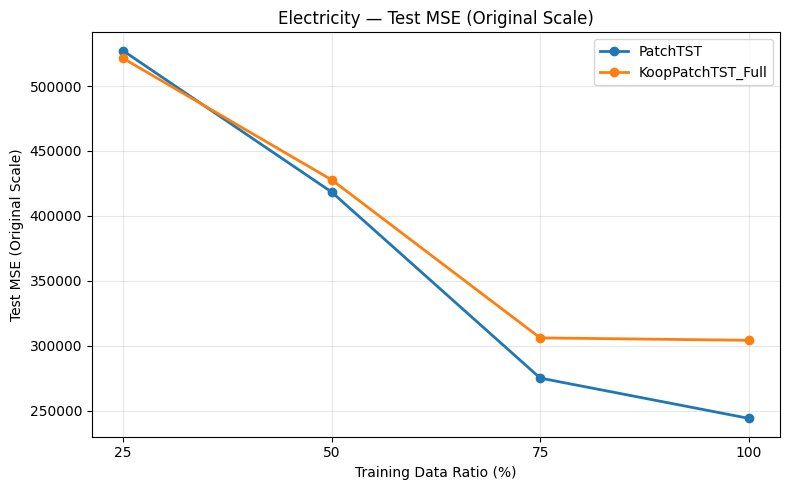

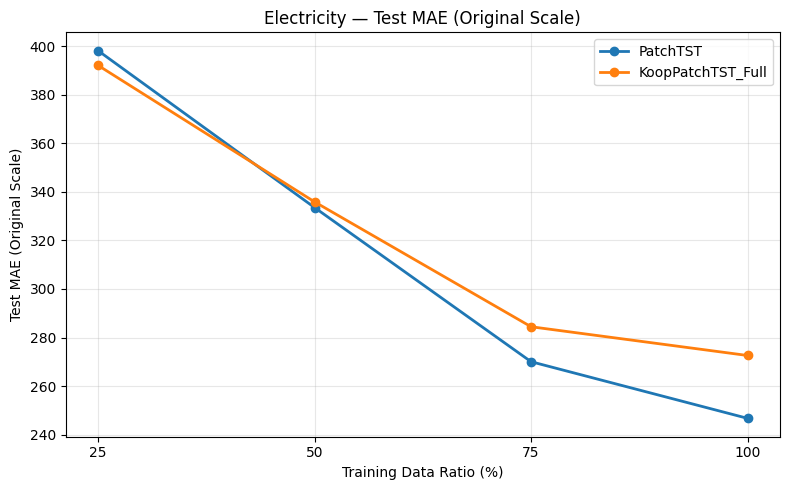

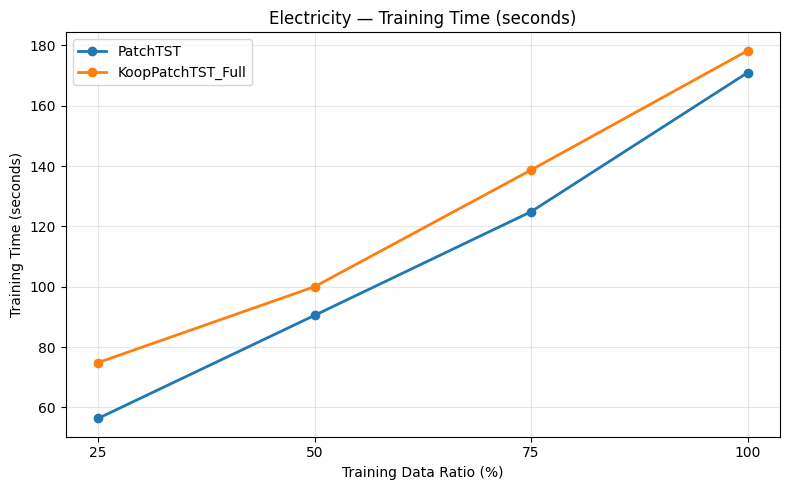

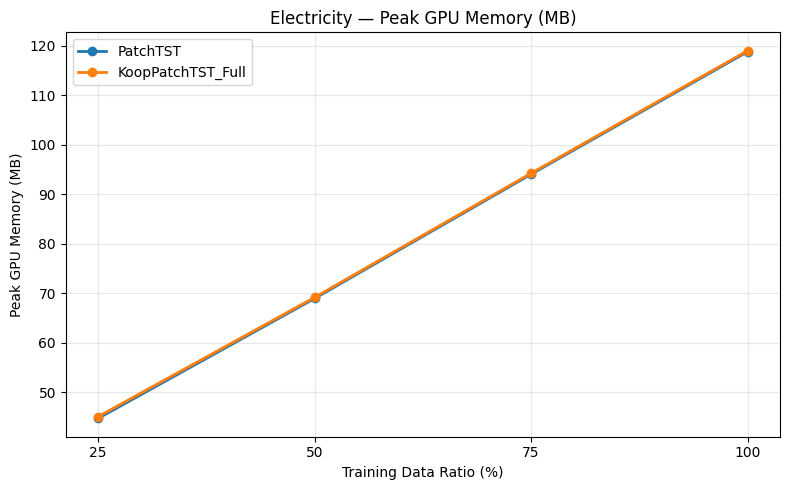

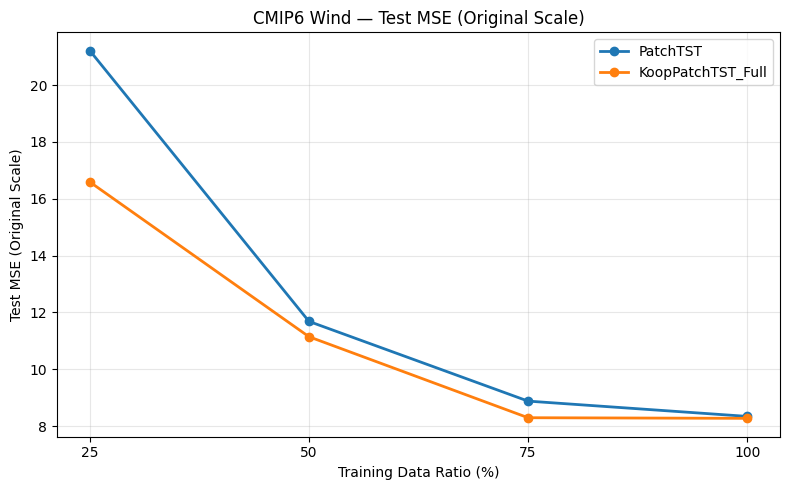

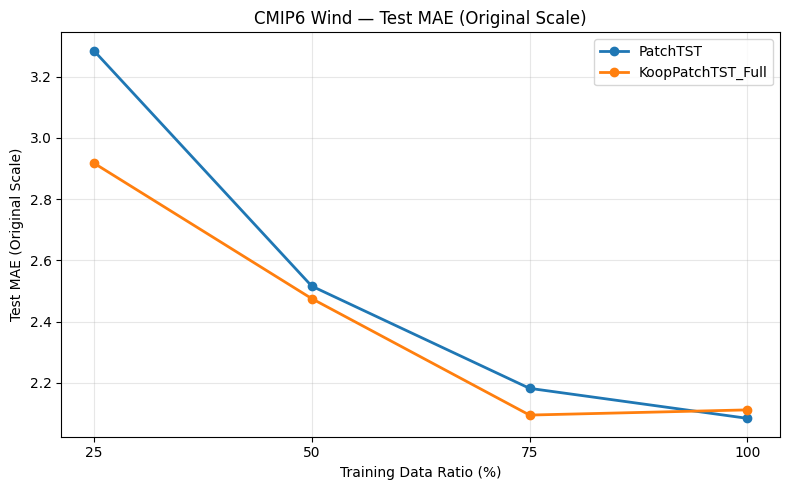

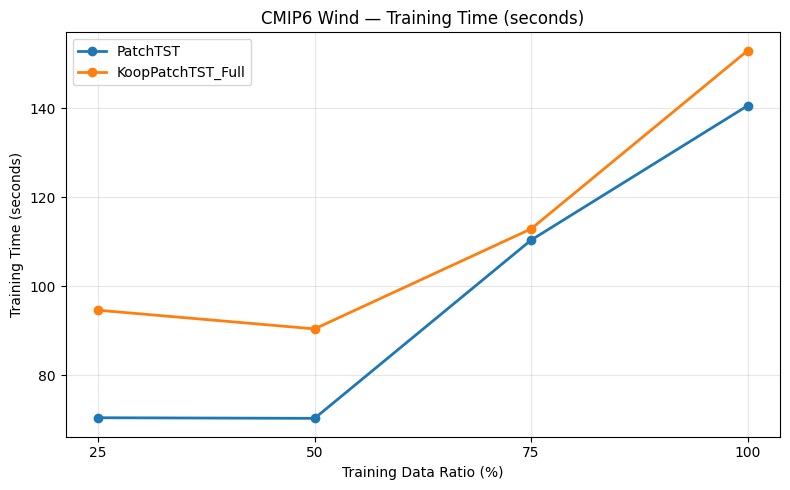

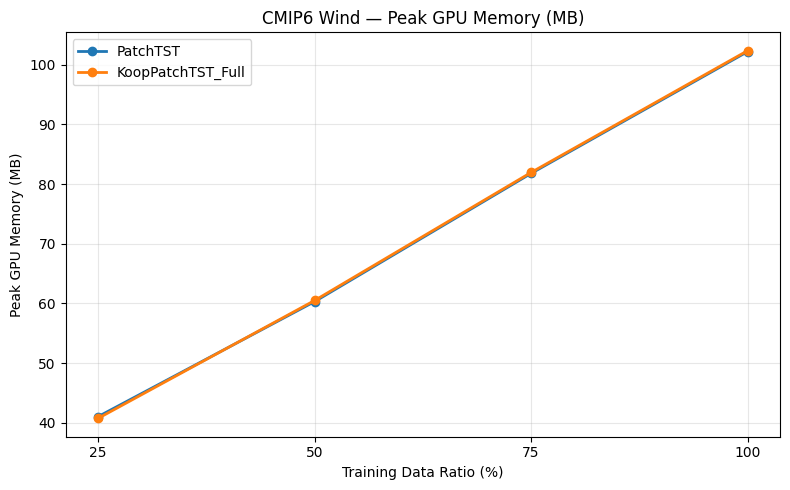


All 8 scalability figures saved!
Output: c:\Users\Win 11 New\Desktop\pa gk\experiments\06_scalability\results\e1_data_scaling\figures


In [8]:
import matplotlib.pyplot as plt

# 1. Load completed results
df = pd.read_csv(RESULTS_DIR / "metrics.csv")
df = df[df["Split"] == "Test"].copy()

FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# 2. Metrics to visualize
METRICS = {
    "MSE": "Test MSE (Original Scale)",
    "MAE": "Test MAE (Original Scale)",
    "Train_Seconds": "Training Time (seconds)",
    "Peak_GPU_MB": "Peak GPU Memory (MB)"
}

# 3. Plot each dataset and metric
for dataset_name in DATASET_FILES:

    subset = df[df["Dataset"] == dataset_name]

    for metric, ylabel in METRICS.items():

        plt.figure(figsize=(8, 5))

        for model_name in MODEL_NAMES:

            model_df = subset[
                subset["Model"] == model_name
            ].sort_values("Train_Ratio")

            plt.plot(
                model_df["Train_Ratio"] * 100,
                model_df[metric],
                marker="o",
                linewidth=2,
                label=model_name
            )

        plt.title(f"{dataset_name} — {ylabel}")
        plt.xlabel("Training Data Ratio (%)")
        plt.ylabel(ylabel)

        plt.xticks([25, 50, 75, 100])
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()

        # 4. Save figure
        filename = (
            dataset_name.lower().replace(" ", "_")
            + "_"
            + metric.lower()
            + ".png"
        )

        plt.savefig(
            FIG_DIR / filename,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

print("\nAll 8 scalability figures saved!")
print("Output:", FIG_DIR)
